# Online Retail II: Data Processing, Analysis and Visualisation
### Part E — Technical Documentation

**Module:** Data and AI Essentials  
**Dataset:** Online Retail II  
**Analysis type:** Data preparation, exploratory data analysis and descriptive visualisation  
**Tools:** Python, pandas, NumPy, Matplotlib and Jupyter Notebook

---

## Notebook Guide

This notebook provides a reproducible workflow for examining retail transaction data. Each section includes a short explanation, executable Python code and outputs that should be reviewed after execution.

**Learning objectives**
1. Load and combine worksheets from an Excel workbook.
2. inspect data quality, missing values and data types.
3. Prepare transaction data for descriptive analysis.
4. Calculate filtered transaction revenue and summarise sales patterns.
5. Visualise trends, distributions and country-level differences.
6. Translate observations into practical recommendations while recognising analytical limitations.

**How to use this notebook**
- Place `online_retail_II.xlsx` in a folder named `data` beside this notebook.
- Run the cells in order from top to bottom.
- Read the explanations before each code cell.
- Review generated tables, printed summaries and charts.
- Confirm that the written interpretations agree with your own outputs before submission.

> **Important:** The analysis describes the filtered records. Revenue is calculated as quantity multiplied by unit price; it is not profit. The notebook does not establish the causes of observed patterns.

## 1. Introduction

Retail transaction data can help organisations understand when sales activity changes, how transaction quantities and unit prices are distributed, and which markets contribute the greatest recorded revenue. However, raw transaction files may contain missing values, cancellation invoices, returns, inconsistent data types and unusually large values. These issues should be considered before interpreting the results.

This notebook uses the **Online Retail II** dataset to conduct a structured descriptive analysis. The main questions are:

1. How does filtered sales revenue change from month to month?
2. How are transaction quantities distributed in relation to unit prices?
3. What does the distribution of unit prices reveal about typical and extreme values?
4. Which countries record the highest filtered sales revenue?

The results are intended to support further investigation and business planning. They should not be treated as a forecast or as evidence of profitability.

## 2. Dataset Description

The Online Retail II workbook used for this assignment is expected to contain two worksheets:

- `Year 2009-2010`
- `Year 2010-2011`

The data records transactions from an online retailer. The expected fields are summarised below.

| Field | Meaning | Use in this notebook |
|---|---|---|
| `Invoice` | Invoice or transaction identifier | Identifies invoices and helps flag cancellation invoices |
| `StockCode` | Product identifier | Helps identify products during data review |
| `Description` | Product description | Provides context for unusual transactions |
| `Quantity` | Number of units recorded | Used in filtering and revenue calculation |
| `InvoiceDate` | Transaction date and time | Used to analyse monthly trends |
| `Price` | Unit price | Used in revenue calculation and price distribution |
| `Customer ID` | Customer identifier | Retained where present; missing values are reported |
| `Country` | Country associated with the transaction | Used for country-level comparison |

### Analytical definition

For this notebook, line-level revenue is calculated as:

\[
\text{Revenue} = \text{Quantity} \times \text{Price}
\]

The visualisations use transactions with positive quantities and positive unit prices. Consequently, the results represent **filtered positive-transaction revenue**, not net revenue after returns and cancellations, and not profit. Costs and operating expenses are not provided in the fields listed above.

## 3. Environment Setup and Data Loading

This section imports the libraries used throughout the notebook and loads both worksheets. A source-sheet label is added before combining the records so that the origin of each row can be traced during inspection.

**Libraries**
- **pandas:** reads the Excel workbook and prepares tabular data.
- **NumPy:** provides numerical operations and is available for additional analysis.
- **Matplotlib:** creates the visualisations.
- **pathlib:** handles the dataset path in a platform-independent way.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Keep figures consistent and readable throughout the notebook.
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 10

BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "online_retail_II.xlsx"
SHEETS = ["Year 2009-2010", "Year 2010-2011"]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Excel workbook not found at: {DATA_PATH.resolve()}\n"
        "Place online_retail_II.xlsx in the data folder or update DATA_PATH."
    )

worksheet_data = {}
for sheet_name in SHEETS:
    worksheet_data[sheet_name] = pd.read_excel(DATA_PATH, sheet_name=sheet_name)
    worksheet_data[sheet_name]["Source_Sheet"] = sheet_name

raw_data = pd.concat(worksheet_data.values(), ignore_index=True)

print("Workbook loaded successfully.")
print(f"Workbook path: {DATA_PATH.resolve()}")
print(f"Combined dataset: {raw_data.shape[0]:,} rows × {raw_data.shape[1]:,} columns")
print("\nRows by worksheet:")
display(
    pd.DataFrame({
        "Worksheet": list(worksheet_data.keys()),
        "Rows": [len(frame) for frame in worksheet_data.values()],
        "Columns": [frame.shape[1] - 1 for frame in worksheet_data.values()]
    })
)

Workbook loaded successfully.
Workbook path: D:\wou\Data and AI Essentials\Assignment2\data\online_retail_II.xlsx
Combined dataset: 1,067,371 rows × 9 columns

Rows by worksheet:


,Worksheet,Rows,Columns
0,Year 2009-2010,525461,8
1,Year 2010-2011,541910,8


## 4. Initial Data Inspection

Before cleaning, inspect the first few records, dimensions, column names, data types, missing values and duplicate rows. These checks help identify issues that may affect later calculations.

A duplicate-row count is only a diagnostic. A row should not be deleted automatically just because it appears duplicated: repeated transaction lines may be legitimate. Similarly, missing customer identifiers do not necessarily make a transaction unusable for monthly or country-level summaries.

In [3]:
print("Sample records:")
display(raw_data.head(8))

print("Dataset dimensions:", raw_data.shape)
print("\nColumn names:")
print(raw_data.columns.tolist())

print("\nData types:")
display(raw_data.dtypes.rename("Data type").to_frame())

missing_report = (
    raw_data.isna().sum()
    .rename("Missing count")
    .to_frame()
)
missing_report["Missing percentage"] = (
    missing_report["Missing count"] / len(raw_data) * 100
).round(2)
display(missing_report.sort_values("Missing count", ascending=False))

print("Exact duplicate rows across all columns:",
      int(raw_data.duplicated().sum()))

Sample records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Source_Sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,Year 2009-2010
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,Year 2009-2010


Dataset dimensions: (1067371, 9)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Source_Sheet']

Data types:


,Data type
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
Customer ID,float64
Country,str
Source_Sheet,str


,Missing count,Missing percentage
Customer ID,243007,22.77
Description,4382,0.41
Invoice,0,0.00
Quantity,0,0.00
StockCode,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Source_Sheet,0,0.00


Exact duplicate rows across all columns: 12133


## 5. Data Preparation

The preparation process applies the following steps:

1. Standardise column labels by removing surrounding whitespace.
2. Check that the required columns are present.
3. Convert dates and numerical fields to appropriate types.
4. Fill missing product descriptions with `Unknown description` so they are visible during review.
5. Flag invoices whose identifier begins with `C`; the flag is retained for transparency.
6. Remove rows with missing or invalid date, quantity, price or country values from the prepared analysis table.
7. Calculate line-level revenue.
8. Create a year-month field for monthly aggregation.
9. Create a positive-transaction subset for the visualisations.

**Data-handling decision:** Missing `Customer ID` values are retained because customer identification is not required for these analyses. Cancellation invoices are flagged, but the visualisation subset is defined by positive quantity and positive price. This is a descriptive filter, not a complete accounting reconciliation of returns or cancellations.

In [4]:
data = raw_data.copy()
data.columns = [str(column).strip() for column in data.columns]

required_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country"
]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(f"Required columns not found: {missing_columns}")

# Convert fields to appropriate types. Invalid values become missing (NaN/NaT).
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")
data["Quantity"] = pd.to_numeric(data["Quantity"], errors="coerce")
data["Price"] = pd.to_numeric(data["Price"], errors="coerce")

# Preserve missing customer IDs; label missing descriptions for review.
data["Description"] = data["Description"].fillna("Unknown description")

# Flag cancellation invoice identifiers without deleting them at this stage.
invoice_text = data["Invoice"].astype("string").str.strip().str.upper()
data["Is_Cancellation"] = invoice_text.str.startswith("C", na=False)

rows_before_required_filter = len(data)
data = data.dropna(
    subset=["InvoiceDate", "Quantity", "Price", "Country"]
).copy()
rows_removed = rows_before_required_filter - len(data)

# Calculate revenue at transaction-line level.
data["Revenue"] = data["Quantity"] * data["Price"]
data["YearMonth"] = data["InvoiceDate"].dt.to_period("M").astype(str)
data["Year"] = data["InvoiceDate"].dt.year

# Positive-transaction subset used in the charts and primary comparisons.
sales = data.loc[
    (data["Quantity"] > 0) & (data["Price"] > 0)
].copy()

preparation_summary = pd.DataFrame({
    "Measure": [
        "Rows in combined raw data",
        "Rows removed for missing/invalid required analysis fields",
        "Rows in prepared data",
        "Rows in positive-transaction subset",
        "Cancellation invoices flagged in prepared data",
        "Missing customer IDs retained in prepared data",
        "Countries represented in positive-transaction subset"
    ],
    "Value": [
        len(raw_data),
        rows_removed,
        len(data),
        len(sales),
        int(data["Is_Cancellation"].sum()),
        int(data["Customer ID"].isna().sum()),
        int(sales["Country"].nunique())
    ]
})
display(preparation_summary)
print("Prepared sample:")
display(sales.head())

,Measure,Value
0,Rows in combined raw data,1067371
1,Rows removed for missing/invalid required anal...,0
2,Rows in prepared data,1067371
3,Rows in positive-transaction subset,1041671
4,Cancellation invoices flagged in prepared data,19494
5,Missing customer IDs retained in prepared data,243007
6,Countries represented in positive-transaction ...,43


Prepared sample:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Source_Sheet,Is_Cancellation,Revenue,YearMonth,Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,83.4,2009-12,2009
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,81.0,2009-12,2009
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,81.0,2009-12,2009
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,100.8,2009-12,2009
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,30.0,2009-12,2009


## 6. Exploratory Data Analysis

Exploratory data analysis (EDA) summarises the prepared records before visual interpretation. The numerical summary includes quantity, unit price and calculated revenue. The country and monthly summaries identify the largest totals and provide tables that can be checked against the charts.

In [5]:
numerical_summary = sales[["Quantity", "Price", "Revenue"]].describe().T
display(numerical_summary)

total_filtered_revenue = sales["Revenue"].sum()
print(f"Total filtered positive-transaction revenue: {total_filtered_revenue:,.2f}")
print(f"Median unit price: {sales['Price'].median():,.2f}")
print(f"Median quantity: {sales['Quantity'].median():,.2f}")

country_revenue = (
    sales.groupby("Country", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
country_revenue.index = country_revenue.index + 1
country_revenue.index.name = "Rank"

monthly_revenue = (
    sales.groupby("YearMonth", as_index=False)["Revenue"]
    .sum()
    .sort_values("YearMonth")
    .reset_index(drop=True)
)

print("\nTop 10 countries by filtered revenue:")
display(country_revenue.head(10))

print("\nFirst 10 monthly totals:")
display(monthly_revenue.head(10))

,count,mean,std,min,25%,50%,75%,max
Quantity,1041671.0,10.963448,126.514930,1.000,1.00,3.00,10.00,80995.00
Price,1041671.0,4.077038,51.448979,0.001,1.25,2.10,4.13,25111.09
Revenue,1041671.0,20.133966,203.116653,0.001,3.90,9.96,17.70,168469.60


Total filtered positive-transaction revenue: 20,972,968.14
Median unit price: 2.10
Median quantity: 3.00

Top 10 countries by filtered revenue:


,Country,Revenue
Rank,,
1,United Kingdom,1.787135e+07
2,EIRE,6.644318e+05
3,Netherlands,5.542323e+05
4,Germany,4.312625e+05
5,France,3.569446e+05
6,Australia,1.699681e+05
7,Spain,1.091785e+05
8,Switzerland,1.010113e+05
9,Sweden,9.190372e+04



First 10 monthly totals:


,YearMonth,Revenue
0,2009-12,825685.760
1,2010-01,652708.502
2,2010-02,553713.306
3,2010-03,833570.131
4,2010-04,681528.992
5,2010-05,659858.860
6,2010-06,752270.140
7,2010-07,650712.940
8,2010-08,697274.910
9,2010-09,924333.011


## 7. Visualisations

The four visualisations answer different questions. The line plot focuses on time, the scatter plot compares two numerical fields, the histogram shows the distribution of unit prices, and the bar chart compares countries. Titles, axis labels and legends are included to make the figures understandable outside the code.

### 7.1 Line Plot — Monthly Filtered Sales Revenue
**Purpose:** identify months with higher or lower filtered transaction revenue. The final month in the dataset may be incomplete, so it should not be compared directly with complete months.

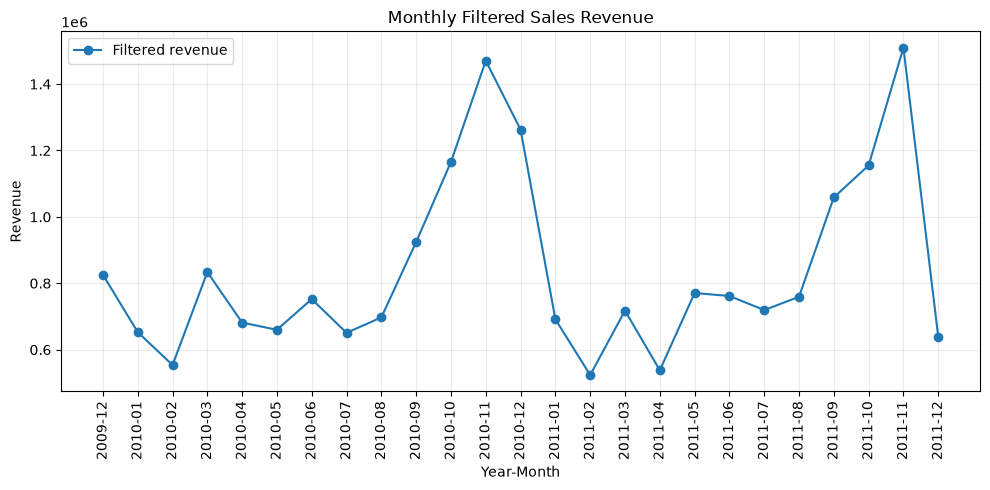

Highest observed month: 2011-11 (revenue: 1,509,496.33)


In [6]:
fig, ax = plt.subplots()
ax.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=1.5,
    label="Filtered revenue"
)
ax.set_title("Monthly Filtered Sales Revenue")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Revenue")
ax.tick_params(axis="x", rotation=90)
ax.legend()
fig.tight_layout()
plt.show()

peak_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmax()]
print(
    f"Highest observed month: {peak_month['YearMonth']} "
    f"(revenue: {peak_month['Revenue']:,.2f})"
)

### 7.2 Scatter Plot — Quantity Versus Unit Price
**Purpose:** examine the concentration of transactions and identify unusual combinations of quantity and price. A scatter plot can reveal patterns, but it does not by itself establish causation.

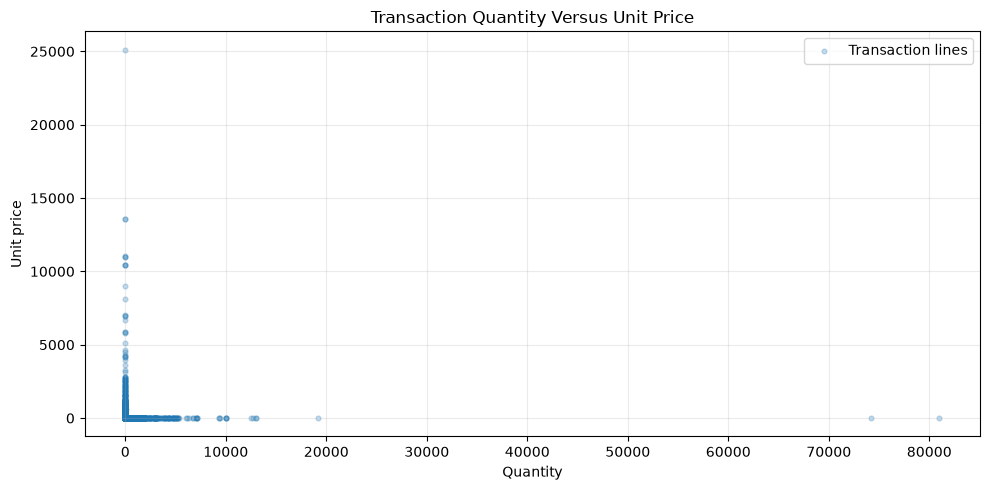

Pearson correlation (descriptive only): -0.0038


In [7]:
fig, ax = plt.subplots()
ax.scatter(sales["Quantity"], sales["Price"], alpha=0.25, s=12, label="Transaction lines")
ax.set_title("Transaction Quantity Versus Unit Price")
ax.set_xlabel("Quantity")
ax.set_ylabel("Unit price")
ax.legend()
fig.tight_layout()
plt.show()

correlation = sales[["Quantity", "Price"]].corr().iloc[0, 1]
print(f"Pearson correlation (descriptive only): {correlation:.4f}")

### 7.3 Histogram — Distribution of Unit Prices
**Purpose:** show whether transaction unit prices cluster in lower price ranges and whether the distribution has a long tail. Extreme values should be checked rather than removed automatically.

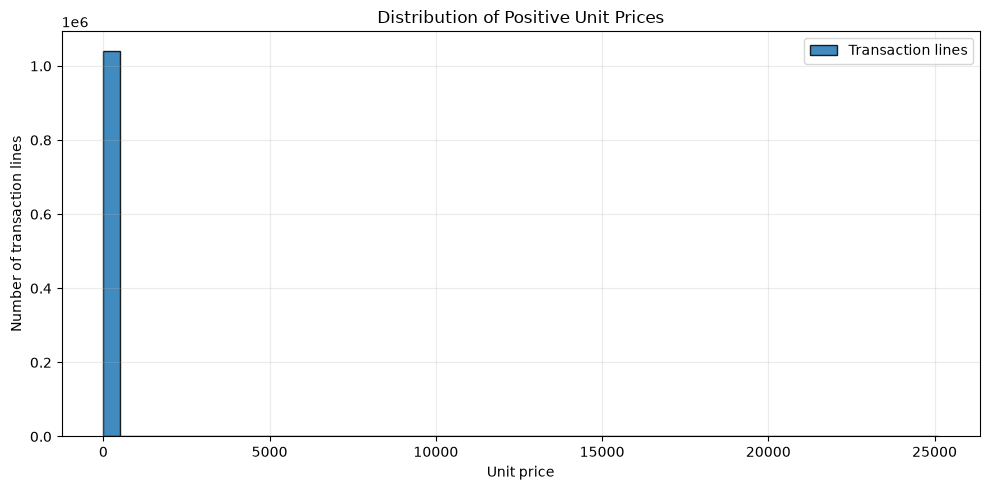

,Value
Median unit price,2.10
95th percentile,9.95
99th percentile,18.00
Maximum unit price,25111.09


In [8]:
fig, ax = plt.subplots()
ax.hist(sales["Price"], bins=50, edgecolor="black", alpha=0.85, label="Transaction lines")
ax.set_title("Distribution of Positive Unit Prices")
ax.set_xlabel("Unit price")
ax.set_ylabel("Number of transaction lines")
ax.legend()
fig.tight_layout()
plt.show()

price_statistics = pd.Series({
    "Median unit price": sales["Price"].median(),
    "95th percentile": sales["Price"].quantile(0.95),
    "99th percentile": sales["Price"].quantile(0.99),
    "Maximum unit price": sales["Price"].max()
}).round(2)
display(price_statistics.to_frame("Value"))

### 7.4 Bar Chart — Top 10 Countries by Filtered Revenue
**Purpose:** compare the ten countries with the largest filtered revenue totals. Revenue indicates transaction value, not profitability.

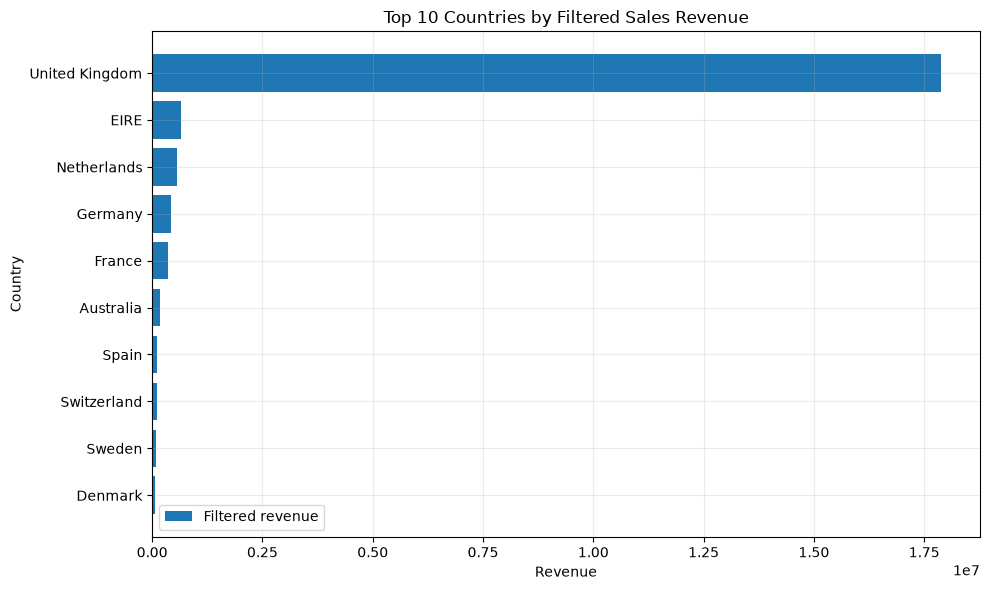

,Country,Revenue
Rank,,
1,United Kingdom,1.787135e+07
2,EIRE,6.644318e+05
3,Netherlands,5.542323e+05
4,Germany,4.312625e+05
5,France,3.569446e+05
6,Australia,1.699681e+05
7,Spain,1.091785e+05
8,Switzerland,1.010113e+05
9,Sweden,9.190372e+04


In [9]:
top10_countries = country_revenue.head(10).sort_values("Revenue", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top10_countries["Country"],
    top10_countries["Revenue"],
    label="Filtered revenue"
)
ax.set_title("Top 10 Countries by Filtered Sales Revenue")
ax.set_xlabel("Revenue")
ax.set_ylabel("Country")
ax.legend()
fig.tight_layout()
plt.show()

display(country_revenue.head(10))

## 8. Findings and Interpretation

Use the tables and figures generated above to finalise these evidence-based observations. Avoid inserting figures that do not match the notebook outputs.

1. **Monthly revenue trend:** identify the highest-revenue month from the printed output and describe noticeable rises and falls in the line plot. Treat the final partial month cautiously.
2. **Quantity and unit price:** describe where most points are concentrated and whether a small number of extreme values are present. The correlation is descriptive and does not demonstrate cause and effect.
3. **Unit-price distribution:** use the histogram and percentile table to describe the main concentration and right tail, if visible. High values should be investigated before being labelled errors.
4. **Country-level comparison:** use the ranked table to identify the highest-revenue country and compare its total with other countries. These totals represent filtered revenue, not profit.

## 9. Recommendations

The following recommendations are linked to the descriptive results and should be refined after reviewing the generated outputs.

### Recommendation 1 — Improve inventory planning
Investigate months with unusually high revenue and compare them with product-level demand, stock availability and supplier lead times. If peaks recur, use that evidence to plan inventory in advance. Monthly revenue alone is not enough to predict demand for each product.

### Recommendation 2 — Review unusual transactions
Create a review process for exceptionally high quantities or unit prices. Check invoice details, product descriptions and source records before making corrections. Legitimate high-value transactions should be retained.

### Recommendation 3 — Evaluate market opportunities
Maintain service and product availability in the highest-revenue markets while investigating opportunities in other countries. Consider logistics, customer demand, marketing costs and profitability before allocating additional resources.

## 10. Limitations

- **Historical coverage:** the workbook covers December 2009 to December 2011, so it may not represent current purchasing behaviour or market conditions.
- **Partial final month:** December 2011 contains only part of the month and is not directly comparable with full-month totals.
- **Filtering decisions:** the visualisations use positive quantities and positive unit prices. Returns and cancellation activity are therefore not represented as negative values in these charts.
- **Revenue versus profit:** quantity multiplied by unit price does not include cost of goods, operating expenses or other costs. Profitability cannot be determined.
- **Extreme values:** high quantities and prices can affect chart scales and summary statistics. They should be investigated, not automatically deleted.
- **Descriptive method:** the analysis identifies patterns but does not establish the reasons behind them, predict future results, or prove that the recommendations will cause improved performance.

## 11. Conclusion

This notebook presents a structured workflow for loading, inspecting, preparing, analysing and visualising the Online Retail II transaction data. The resulting tables and charts describe monthly filtered revenue, the distribution of quantities and unit prices, and country-level differences. These observations can support further investigation into inventory planning, transaction quality and market performance.

The results should be interpreted with the data limitations in mind. In particular, filtered revenue should not be confused with profit, and historical patterns should be verified against current business data before operational decisions are made.

## 12. References

Chen, D. (2012). *Online Retail II* [Data set]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/502/online+retail+ii

pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

Project Jupyter. (n.d.). *Project Jupyter documentation*. https://docs.jupyter.org/